# TP5 - Visualización de Datos
Materia: Diseño de Bases de Datos II  
Carrera: Ingeniería en Informática - Universidad de Mendoza  
Alumno: Francisco Rodeles  

## Consigna

Seleccionar tres gráficos con mala visualización.

- <a href="https://www.consultantsmind.com/2017/04/10/bad-charts/"> Página 1 </a>
- <a href="https://badvisualisations.tumblr.com/"> Página 2 </a>
- <a href="https://flowingdata.com/category/visualization/ugly-visualization/"> Página 3 </a>

Para cada gráfico:

- Mostrar una imagen del gráfico
- Explicar por qué es una mala representación
- Utilizar Matplotlib para representar correctamente los datos

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## Gráfico 1: Ingreso promedio por usuario en Facebook (Worldwide vs. US & Canada)

### 1.1 Imagen del gráfico original
Fuente: Página 1 (Consultant's Mind - Anti-example: 10 bad charts)

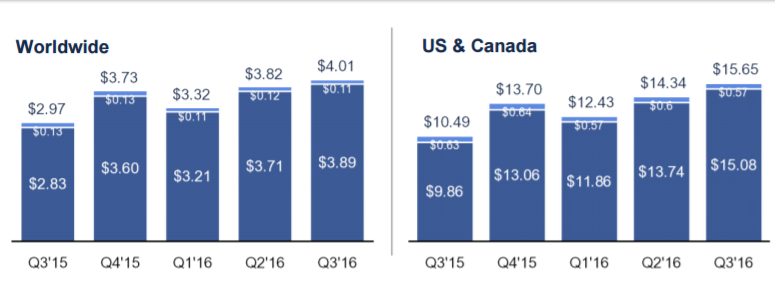

### 1.2 Por qué es una mala representación

- Escalas incompatibles lado a lado: El gráfico ubica dos series de barras a la misma altura visual, pero cada una tiene una escala implícita totalmente diferente. La barra de Q3'16 a nivel mundial ($4.01) tiene exactamente el mismo alto en pantalla que la barra de Q3'16 en Estados Unidos y Canadá ($15.65), cuando en realidad esta última es casi cuatro veces mayor.
- Ausencia de eje vertical y unidades: No existe eje Y ni indicación de escala, obligando a leer número por número para entender la diferencia real de magnitud entre ambas regiones.
- Falta de leyenda: Las barras están divididas en dos tonos de azul (ingresos por publicidad e ingresos por pagos/otros), pero no se incluye ninguna leyenda que explique qué representa cada color.

### 1.3 Representación correcta con Matplotlib

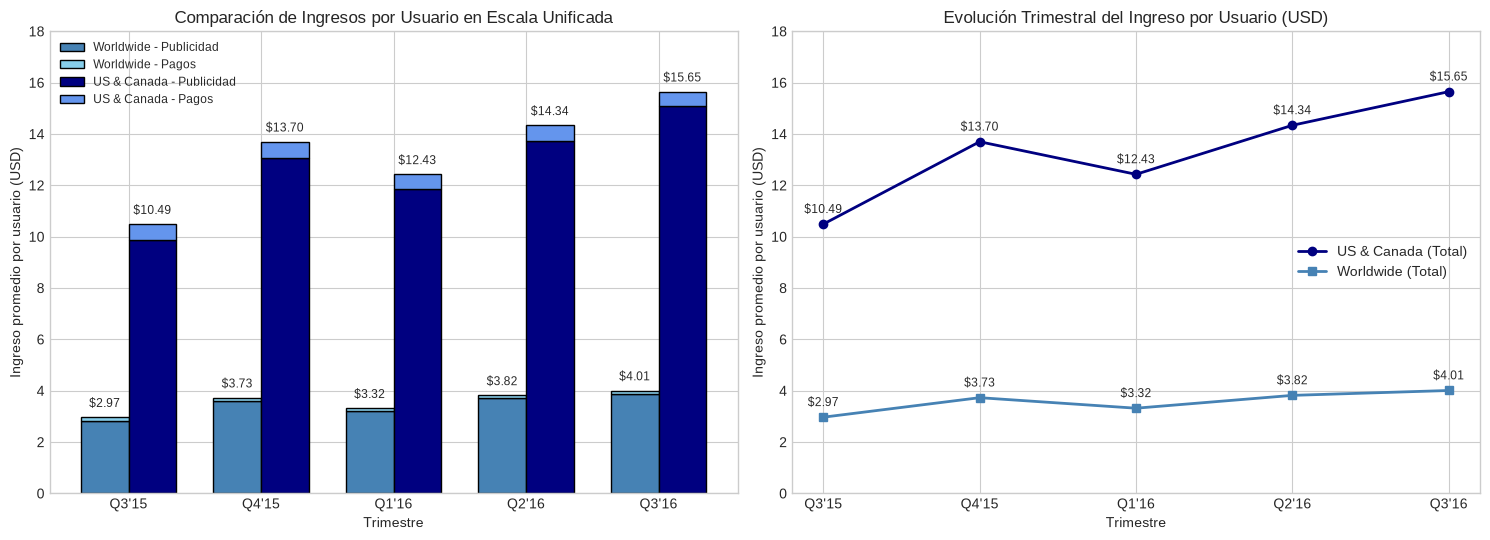

In [2]:
trimestres = ["Q3'15", "Q4'15", "Q1'16", "Q2'16", "Q3'16"]

# Datos extraídos del gráfico original (en dólares USD)
ww_publicidad = [2.83, 3.60, 3.21, 3.71, 3.89]
ww_pagos = [0.13, 0.13, 0.11, 0.12, 0.11]
ww_total = [2.97, 3.73, 3.32, 3.82, 4.01]

us_publicidad = [9.86, 13.06, 11.86, 13.74, 15.08]
us_pagos = [0.63, 0.64, 0.57, 0.60, 0.57]
us_total = [10.49, 13.70, 12.43, 14.34, 15.65]

x = np.arange(len(trimestres))
ancho = 0.36

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Gráfico de barras comparadas bajo una misma escala común
axes[0].bar(x - ancho/2, ww_publicidad, width=ancho, color='steelblue', edgecolor='black', label='Worldwide - Publicidad')
axes[0].bar(x - ancho/2, ww_pagos, bottom=ww_publicidad, width=ancho, color='skyblue', edgecolor='black', label='Worldwide - Pagos')

axes[0].bar(x + ancho/2, us_publicidad, width=ancho, color='navy', edgecolor='black', label='US & Canada - Publicidad')
axes[0].bar(x + ancho/2, us_pagos, bottom=us_publicidad, width=ancho, color='cornflowerblue', edgecolor='black', label='US & Canada - Pagos')

for i in range(len(trimestres)):
    axes[0].text(x[i] - ancho/2, ww_total[i] + 0.3, f"${ww_total[i]:.2f}", ha='center', va='bottom', fontsize=8.5)
    axes[0].text(x[i] + ancho/2, us_total[i] + 0.3, f"${us_total[i]:.2f}", ha='center', va='bottom', fontsize=8.5)

axes[0].set_xticks(x)
axes[0].set_xticklabels(trimestres)
axes[0].set_ylim(0, 18)
axes[0].set_xlabel('Trimestre')
axes[0].set_ylabel('Ingreso promedio por usuario (USD)')
axes[0].set_title('Comparación de Ingresos por Usuario en Escala Unificada')
axes[0].legend(loc='upper left', fontsize=8.5)

# 2. Gráfico de líneas para comparar la evolución temporal de ambas regiones
axes[1].plot(trimestres, us_total, marker='o', linewidth=2, color='navy', label='US & Canada (Total)')
axes[1].plot(trimestres, ww_total, marker='s', linewidth=2, color='steelblue', label='Worldwide (Total)')

for i, txt in enumerate(us_total):
    axes[1].annotate(f"${txt:.2f}", (trimestres[i], us_total[i]), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8.5)
for i, txt in enumerate(ww_total):
    axes[1].annotate(f"${txt:.2f}", (trimestres[i], ww_total[i]), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8.5)

axes[1].set_ylim(0, 18)
axes[1].set_xlabel('Trimestre')
axes[1].set_ylabel('Ingreso promedio por usuario (USD)')
axes[1].set_title('Evolución Trimestral del Ingreso por Usuario (USD)')
axes[1].legend(loc='center right')

plt.tight_layout()
plt.show()

---
## Gráfico 2: Evolución del EBITDA de Ambev (2010 a 2015)

### 2.1 Imagen del gráfico original
Fuente: Página 1 (Consultant's Mind - Anti-example: 10 bad charts)

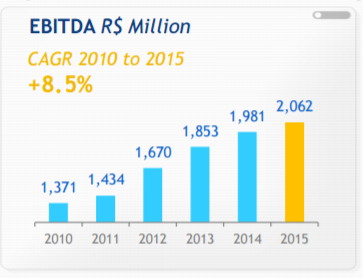

### 2.2 Por qué es una mala representación

- Eje vertical truncado y oculto: En los gráficos de barras, el ojo humano compara cantidades a partir de la longitud completa de cada barra desde la línea base. Al no comenzar el eje Y en cero (sino cerca de 1.200) y además ocultar la escala vertical, la barra de 2010 (1.371 millones) parece cinco veces más chica que la de 2015 (2.062 millones).
- Exageración de la pendiente de crecimiento: En la realidad el incremento total entre 2010 y 2015 fue del 50,4% (un crecimiento anual compuesto del 8,5%), pero el recorte de la base simula visualmente una multiplicación por cinco.

### 2.3 Representación correcta con Matplotlib

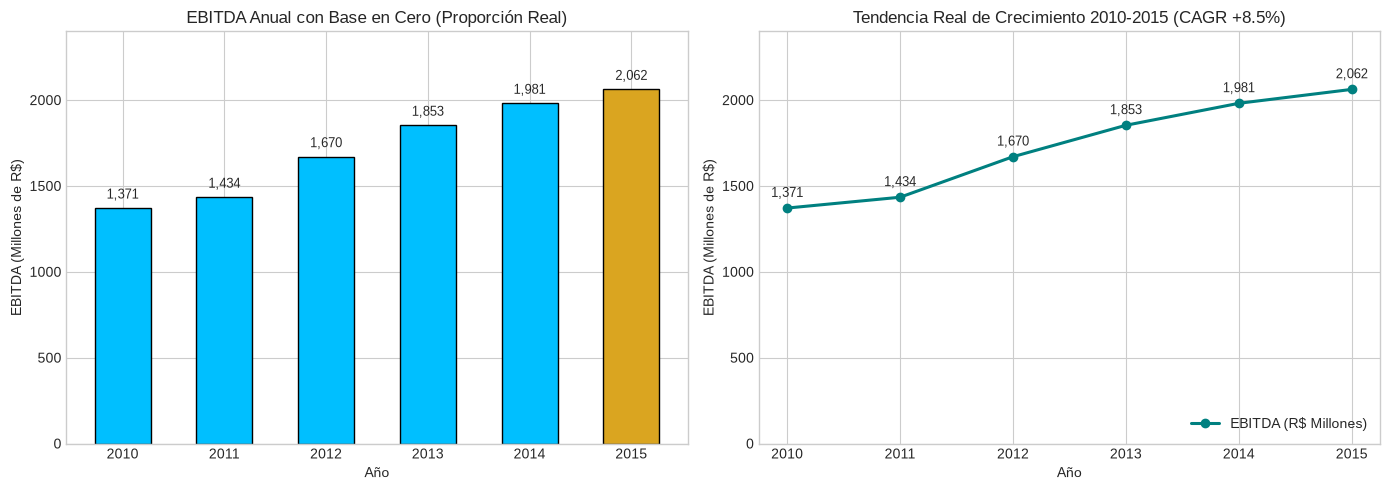

In [3]:
anios = ['2010', '2011', '2012', '2013', '2014', '2015']
ebitda = [1371, 1434, 1670, 1853, 1981, 2062]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfico de barras con eje Y comenzando estrictamente en 0
colores_barras = ['deepskyblue'] * 5 + ['goldenrod']
barras = axes[0].bar(anios, ebitda, color=colores_barras, edgecolor='black', width=0.55)
axes[0].set_ylim(0, 2400)
axes[0].set_xlabel('Año')
axes[0].set_ylabel('EBITDA (Millones de R$)')
axes[0].set_title('EBITDA Anual con Base en Cero (Proporción Real)')

for b in barras:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 40, f"{h:,}", ha='center', va='bottom', fontsize=9)

# 2. Gráfico de líneas con base en cero para mostrar la tendencia (+8.5% CAGR)
axes[1].plot(anios, ebitda, marker='o', color='teal', linewidth=2.2, label='EBITDA (R$ Millones)')
axes[1].set_ylim(0, 2400)
axes[1].set_xlabel('Año')
axes[1].set_ylabel('EBITDA (Millones de R$)')
axes[1].set_title('Tendencia Real de Crecimiento 2010-2015 (CAGR +8.5%)')

for i, val in enumerate(ebitda):
    axes[1].annotate(f"{val:,}", (anios[i], ebitda[i]), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)

axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

---
## Gráfico 3: Puntualidad en Salidas de Vuelos de United Airlines (FY14 a FY16)

### 3.1 Imagen del gráfico original
Fuente: Página 1 (Consultant's Mind - Anti-example: 10 bad charts)

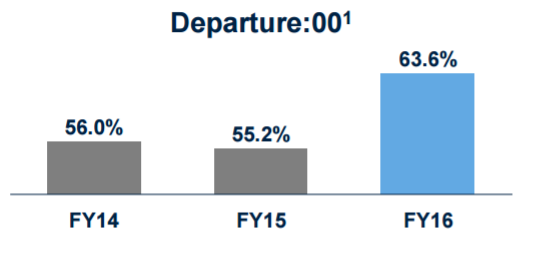

### 3.2 Por qué es una mala representación

- Distorsión de porcentajes por recorte de base: Los valores representados son porcentajes (56.0%, 55.2% y 63.6%), pero la base del gráfico se cortó alrededor del 48% y se eliminó el eje Y. Como consecuencia, el valor de FY16 (63.6%) parece casi el triple de alto que el de FY15 (55.2%), cuando la mejora real fue de apenas 8.4 puntos porcentuales.
- Falta de contexto sobre el 100%: Al tratarse de una proporción sobre el total de vuelos, ocultar el rango de 0% a 100% impide ver qué fracción del total de vuelos siguió saliendo con demora (más de un tercio de los vuelos en FY16).

### 3.3 Representación correcta con Matplotlib

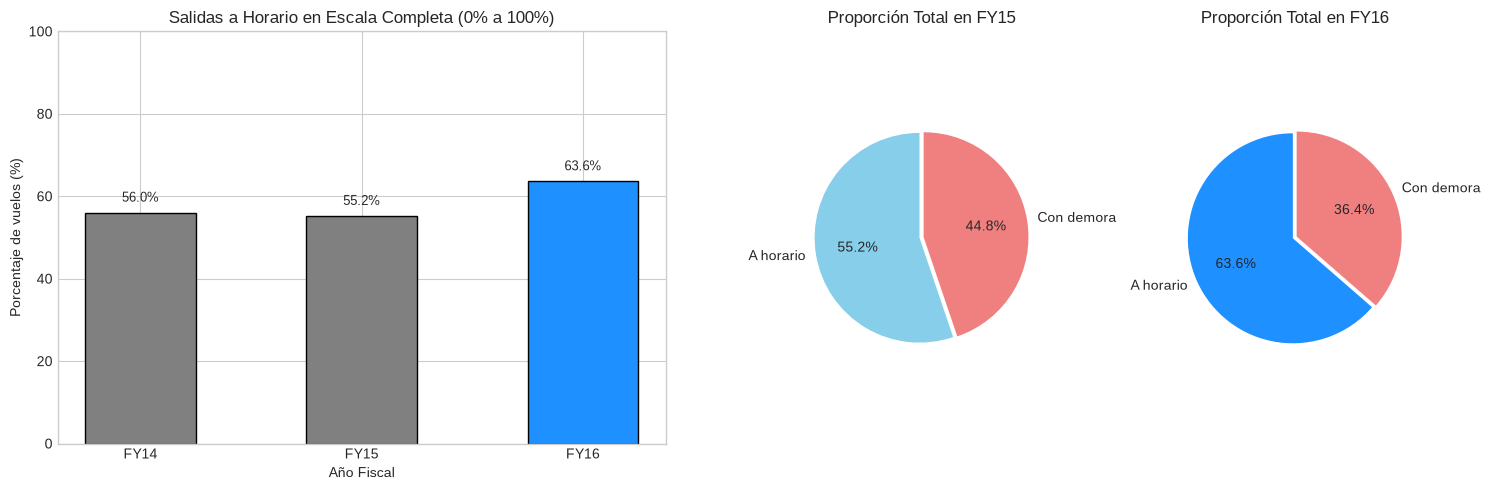

In [4]:
periodos = ['FY14', 'FY15', 'FY16']
puntuales = [56.0, 55.2, 63.6]
demorados = [100 - p for p in puntuales]

fig = plt.figure(figsize=(15, 5))

# 1. Gráfico de barras en escala completa de 0% a 100%
ax1 = plt.subplot2grid((1, 4), (0, 0), colspan=2)
barras_u = ax1.bar(periodos, puntuales, color=['gray', 'gray', 'dodgerblue'], edgecolor='black', width=0.5)
ax1.set_ylim(0, 100)
ax1.set_xlabel('Año Fiscal')
ax1.set_ylabel('Porcentaje de vuelos (%)')
ax1.set_title('Salidas a Horario en Escala Completa (0% a 100%)')

for b in barras_u:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2, h + 2, f"{h:.1f}%", ha='center', va='bottom', fontsize=9.5)

# 2. Gráfico de torta para FY15 vs FY16 mostrando la proporción real sobre el total de vuelos
ax2 = plt.subplot2grid((1, 4), (0, 2))
ax2.pie(
    [puntuales[1], demorados[1]],
    labels=['A horario', 'Con demora'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['skyblue', 'lightcoral'],
    explode=(0.04, 0)
)
ax2.set_title('Proporción Total en FY15')
ax2.axis('equal')

ax3 = plt.subplot2grid((1, 4), (0, 3))
ax3.pie(
    [puntuales[2], demorados[2]],
    labels=['A horario', 'Con demora'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['dodgerblue', 'lightcoral'],
    explode=(0.04, 0)
)
ax3.set_title('Proporción Total en FY16')
ax3.axis('equal')

plt.tight_layout()
plt.show()